In [1]:
import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from torchvision.transforms import InterpolationMode

# Mengunci seed agar hasil eksperimen dapat direproduksi (reproducible)
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

In [2]:
# Konfigurasi direktori dan hyperparameter
BASE_DIR = r'C:\Users\taufi\Documents\Model - TA\datasets\dataset_tahap_1_split'
OUTPUT_DIR = r'C:\Users\taufi\Documents\Code - TA\avocascan-ai\models\stage1'
BATCH_SIZE = 16
NUM_EPOCHS = 30
LEARNING_RATE = 1e-4
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Device           : {DEVICE}")
print(f"Batch Size       : {BATCH_SIZE}")
print(f"Epochs           : {NUM_EPOCHS}")
print(f"Learning Rate    : {LEARNING_RATE}")
print(f"Output Directory : {OUTPUT_DIR}")

os.makedirs(OUTPUT_DIR, exist_ok=True)

Device           : cuda
Batch Size       : 16
Epochs           : 30
Learning Rate    : 0.0001
Output Directory : C:\Users\taufi\Documents\Code - TA\avocascan-ai\models\stage1


In [3]:
# Augmentasi data untuk training
train_transform = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.GaussianBlur(kernel_size=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Transformasi dasar untuk validasi dan testing
val_transform = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Memuat dataset
train_dataset = datasets.ImageFolder(os.path.join(BASE_DIR, 'train'), transform=train_transform)
val_dataset = datasets.ImageFolder(os.path.join(BASE_DIR, 'val'), transform=val_transform)
test_dataset = datasets.ImageFolder(os.path.join(BASE_DIR, 'test'), transform=val_transform)

class_names = train_dataset.classes
print(f"Classes           : {class_names}")
print(f"Train Images      : {len(train_dataset)}")
print(f"Validation Images : {len(val_dataset)}")
print(f"Test Images       : {len(test_dataset)}")

# Membuat dataloader
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

Classes           : ['alpukat', 'non_alpukat']
Train Images      : 237
Validation Images : 50
Test Images       : 52


In [4]:
# Kelas untuk menghentikan proses training jika model tidak lagi berkembang (mencegah overfitting)
class EarlyStopping:
    def __init__(self, patience=3, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.stop = False

    def __call__(self, val_loss):
        improved = val_loss < (self.best_loss - self.min_delta)
        if improved:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True
        return improved

In [5]:
# Memuat arsitektur model pre-trained MobileNetV3 Small
model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)

# Membekukan fitur backbone agar tidak ikut dilatih (transfer learning)
for param in model.features.parameters():
    param.requires_grad = False

# Modifikasi layer klasifikasi akhir menyesuaikan jumlah kelas target
num_features = model.classifier[3].in_features
model.classifier[2] = nn.Dropout(p=0.5)
model.classifier[3] = nn.Linear(num_features, len(class_names))
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.classifier.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)

# Scaler untuk optimasi memory menggunakan mixed precision (AMP)
scaler = torch.amp.GradScaler('cuda' if DEVICE.type == 'cuda' else 'cpu', enabled=DEVICE.type == 'cuda')

In [6]:
def train_one_epoch():
    model.train()
    running_loss = 0.0
    correct, total = 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()

        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

    return running_loss / len(train_loader), 100. * correct / total

def evaluate(loader, return_preds=False):
    model.eval()
    running_loss = 0.0
    correct, total = 0, 0
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            running_loss += loss.item()
            
            # Hitung probabilitas menggunakan softmax untuk grafik ROC
            probs = torch.softmax(outputs, dim=1)
            _, preds = outputs.max(1)
            
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)

            if return_preds:
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
                all_probs.extend(probs[:, 1].cpu().numpy()) # Mengambil probabilitas class positif (index 1)

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100. * correct / total

    if return_preds:
        return epoch_loss, epoch_acc, all_preds, all_labels, all_probs
    return epoch_loss, epoch_acc

In [7]:
early_stopping = EarlyStopping(patience=3, min_delta=0.001)
best_val_loss = float('inf')

train_losses, val_losses = [], []
train_accs, val_accs = [], []

print("Starting Training...\n")
for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_one_epoch()
    val_loss, val_acc = evaluate(val_loader)
    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | LR: {current_lr:.6f} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

    if early_stopping(val_loss):
        best_val_loss = val_loss
        torch.save({
            'model_state_dict': model.state_dict(),
            'class_names': class_names,
            'best_val_loss': best_val_loss
        }, os.path.join(OUTPUT_DIR, 'best_model_tahap1.pth'))
        with open(os.path.join(OUTPUT_DIR, 'class_names.json'), 'w') as f:
            json.dump(class_names, f, indent=4)
        print("   -> Validation loss improved, model and class_names.json saved")
    else:
        print(f"   -> Early stopping counter: {early_stopping.counter}/{early_stopping.patience}")

    if early_stopping.stop:
        print("\nEarly stopping activated")
        break

Starting Training...

Epoch [01/30] | LR: 0.000100 | Train Loss: 0.5883 | Train Acc: 70.04% | Val Loss: 0.6067 | Val Acc: 70.00%
   -> Validation loss improved, model and class_names.json saved
Epoch [02/30] | LR: 0.000100 | Train Loss: 0.4087 | Train Acc: 86.92% | Val Loss: 0.5947 | Val Acc: 74.00%
   -> Validation loss improved, model and class_names.json saved
Epoch [03/30] | LR: 0.000100 | Train Loss: 0.3269 | Train Acc: 89.03% | Val Loss: 0.5575 | Val Acc: 78.00%
   -> Validation loss improved, model and class_names.json saved
Epoch [04/30] | LR: 0.000100 | Train Loss: 0.2746 | Train Acc: 92.41% | Val Loss: 0.5196 | Val Acc: 80.00%
   -> Validation loss improved, model and class_names.json saved
Epoch [05/30] | LR: 0.000100 | Train Loss: 0.2327 | Train Acc: 94.09% | Val Loss: 0.4693 | Val Acc: 88.00%
   -> Validation loss improved, model and class_names.json saved
Epoch [06/30] | LR: 0.000100 | Train Loss: 0.2466 | Train Acc: 89.87% | Val Loss: 0.4039 | Val Acc: 90.00%
   -> Valid

In [8]:
print("\nEVALUATING TEST SET")
test_loss, test_acc, test_preds, test_labels, test_probs = evaluate(test_loader, return_preds=True)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.2f}%\n")

report = classification_report(test_labels, test_preds, target_names=class_names)
print("Classification Report\n")
print(report)

with open(os.path.join(OUTPUT_DIR, 'classification_report_tahap1.txt'), 'w') as f:
    f.write(report)

history = {
    'train_losses': train_losses, 'val_losses': val_losses,
    'train_accs': train_accs, 'val_accs': val_accs
}

with open(os.path.join(OUTPUT_DIR, 'training_history_tahap1.json'), 'w') as f:
    json.dump(history, f, indent=4)


EVALUATING TEST SET
Test Loss     : 0.0788
Test Accuracy : 96.15%

Classification Report

              precision    recall  f1-score   support

     alpukat       0.93      1.00      0.96        26
 non_alpukat       1.00      0.92      0.96        26

    accuracy                           0.96        52
   macro avg       0.96      0.96      0.96        52
weighted avg       0.96      0.96      0.96        52



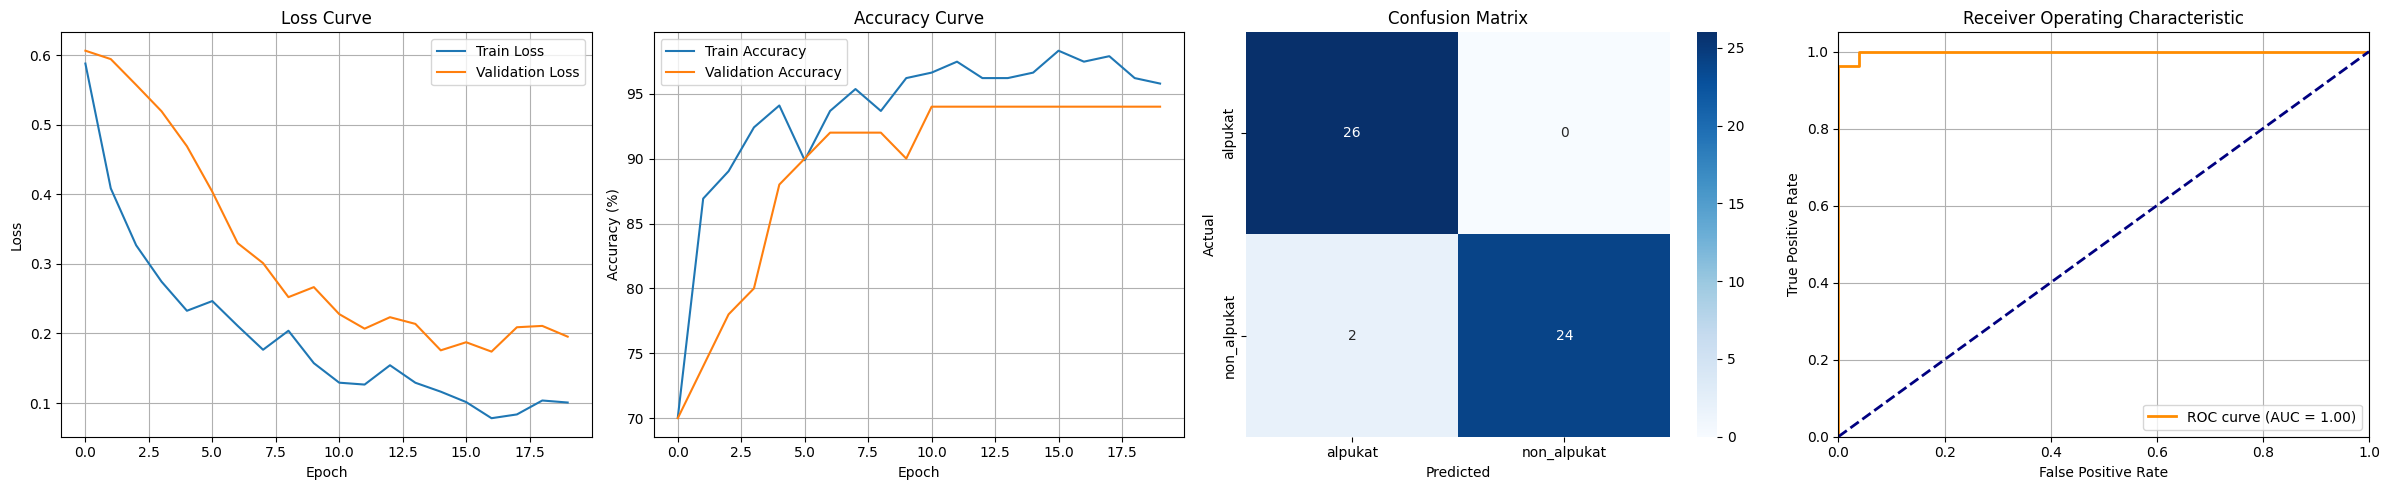


Results saved successfully
Training completed


In [9]:
plt.figure(figsize=(24, 5))

# 1. Loss Curve
plt.subplot(1, 4, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Curve')
plt.legend()
plt.grid(True)

# 2. Accuracy Curve
plt.subplot(1, 4, 2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(val_accs, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy Curve')
plt.legend()
plt.grid(True)

# 3. Confusion Matrix
plt.subplot(1, 4, 3)
cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

# 4. ROC Curve
plt.subplot(1, 4, 4)
fpr, tpr, _ = roc_curve(test_labels, test_probs)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'grafik_evaluasi_tahap1.png'))
plt.show()

print("\nResults saved successfully")
print("Training completed")

In [10]:
import torch
import torch.nn as nn
from torchvision import models
from executorch import exir

print("Semua modul siap!")

# ============================================
# 1. BANGUN ULANG ARSITEKTUR
# ============================================

NUM_CLASSES = 2

model = models.mobilenet_v3_small(weights=None)

model.classifier[2] = nn.Dropout(p=0.5)
model.classifier[3] = nn.Linear(1024, NUM_CLASSES)

checkpoint = torch.load(
    os.path.join(OUTPUT_DIR, "best_model_tahap1.pth"),
    map_location="cpu",
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("✓ Model loaded")

# ============================================
# 2. DUMMY INPUT
# ============================================

example_inputs = (
    torch.randn(1, 3, 224, 224),
)

# ============================================
# 3. EXPORT KE torch.export
# ============================================

exported_program = torch.export.export(
    model,
    example_inputs,
)

print("✓ torch.export selesai")

# ============================================
# 4. CONVERT KE EDGE
# ============================================

edge_program = exir.to_edge(exported_program)

print("✓ Edge Program selesai")

# ============================================
# 5. CONVERT KE EXECUTORCH
# ============================================

executorch_program = edge_program.to_executorch()

print("✓ ExecuTorch Program selesai")

# ============================================
# 6. SIMPAN .PTE
# ============================================

with open(os.path.join(OUTPUT_DIR, "best_model_tahap1.pte"), "wb") as f:
    executorch_program.write_to_file(f)

print("✓ File .pte berhasil dibuat")

ModuleNotFoundError: No module named 'executorch'

In [ ]:
"""
Test satu gambar dengan BACKGROUND DIGANTI PUTIH terlebih dahulu,
untuk menguji hipotesis: apakah model salah prediksi karena background
foto tidak mirip dataset training (yang mayoritas background putih)?

Versi ini pakai GrabCut (OpenCV) + feathering - TIDAK butuh rembg/onnxruntime,
cukup pakai opencv-python yang sudah terinstall.

Cara pakai:
1. Sesuaikan CHECKPOINT_PATH dan IMAGE_PATH di bawah
2. Jalankan: python test_with_white_background.py
"""

import cv2
import numpy as np
import torch
import torch.nn as nn
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from PIL import Image

# ============================================
# KONFIGURASI - SESUAIKAN INI
# ============================================
CHECKPOINT_PATH = r"C:\Users\taufi\Documents\Code - TA\avocascan-ai\models\stage1\best_model_tahap1.pth"
IMAGE_PATH = r"C:\Users\taufi\Documents\Model - TA\datasets\test\IMG_20251217_161257.jpg"
DEBUG_OUTPUT_PATH = "debug_white_bg.jpg"

# ============================================
# 1. FUNGSI GANTI BACKGROUND JADI PUTIH (GRABCUT + FEATHERING)
# ============================================
def replace_background_white(image_path):
    img = cv2.imread(image_path)
    h, w = img.shape[:2]

    # Rect hampir penuh (margin 1 piksel), supaya objek tidak ikut terpotong
    rect = (1, 1, w - 2, h - 2)

    mask = np.zeros((h, w), np.uint8)
    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(img, mask, rect, bgd_model, fgd_model, iterCount=15, mode=cv2.GC_INIT_WITH_RECT)

    # 0=BG, 1=FG, 2=Prob BG, 3=Prob FG -> ubah jadi biner (0 atau 1)
    mask_binary = np.where((mask == 2) | (mask == 0), 0, 1).astype(np.uint8)

    # Morphological closing + opening untuk merapikan mask
    kernel = np.ones((7, 7), np.uint8)
    mask_binary = cv2.morphologyEx(mask_binary, cv2.MORPH_CLOSE, kernel)
    mask_binary = cv2.morphologyEx(mask_binary, cv2.MORPH_OPEN, kernel)

    # Feathering (penghalusan tepi) agar tidak kelihatan kasar
    mask_blur = cv2.GaussianBlur(mask_binary.astype(np.float32), (0, 0), sigmaX=7, sigmaY=7)
    mask_blur = np.clip(mask_blur, 0, 1)

    # Blending dengan background putih
    white_bg = np.ones_like(img, dtype=np.uint8) * 255
    mask_3ch = np.stack([mask_blur] * 3, axis=-1)
    result = (img.astype(np.float32) * mask_3ch + white_bg.astype(np.float32) * (1 - mask_3ch))
    result = result.astype(np.uint8)

    return result


# ============================================
# 2. BANGUN ULANG ARSITEKTUR MODEL
# ============================================
NUM_CLASSES = 2
class_names = ['alpukat', 'non_alpukat']

model = models.mobilenet_v3_small(weights=None)
model.classifier[2] = nn.Dropout(p=0.5)
model.classifier[3] = nn.Linear(1024, NUM_CLASSES)

checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# ============================================
# 3. PREPROCESSING - IDENTIK DENGAN TRAINING
# ============================================
val_transform = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


def predict(pil_image, label_prefix=""):
    input_tensor = val_transform(pil_image).unsqueeze(0)
    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0]
    predicted_idx = torch.argmax(probabilities).item()

    print(f"--- {label_prefix} ---")
    print(f"Probabilitas   : {[f'{p:.4f}' for p in probabilities.tolist()]}")
    print(f"Predicted      : {class_names[predicted_idx]}")
    print(f"Confidence     : {probabilities[predicted_idx].item() * 100:.2f}%\n")


# ============================================
# 4. TEST SEBELUM (kondisi asli)
# ============================================
original_image = Image.open(IMAGE_PATH).convert("RGB")
predict(original_image, "SEBELUM (background asli)")

# ============================================
# 5. TEST SESUDAH (background diganti putih)
# ============================================
white_bg_array = replace_background_white(IMAGE_PATH)
cv2.imwrite(DEBUG_OUTPUT_PATH, white_bg_array)
print(f"Gambar hasil background-removal disimpan di: {DEBUG_OUTPUT_PATH}")
print("*** Cek visual dulu sebelum baca hasil prediksi di bawah ***\n")

white_bg_rgb = cv2.cvtColor(white_bg_array, cv2.COLOR_BGR2RGB)
white_bg_pil = Image.fromarray(white_bg_rgb)
predict(white_bg_pil, "SESUDAH (background diganti putih)")

print("=" * 60)
print("KESIMPULAN:")
print("Kalau prediksi SESUDAH jadi benar (atau confidence 'alpukat' naik drastis),")
print("ini mengonfirmasi background bias adalah penyebab utamanya.")
print("=" * 60)